In [3]:
from pathlib import Path
from time import perf_counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import TruncatedSVD
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (
    roc_auc_score,
    f1_score,
    precision_score,
    recall_score,
    confusion_matrix,
)
from lightgbm import LGBMClassifier


In [4]:
DATA_ROOT = Path(".")
OUT = Path("results")
FIGURES = OUT / "figures"

SEEDS = [2026]
DIMS = [256, 512]
SPLIT_SEED = 20
THREADS = 64
AUC_TOLERANCE = 0.005

OUT.mkdir(exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)


In [5]:
def load_data(filename):
    with np.load(DATA_ROOT / filename, allow_pickle=True) as data:
        y = data["y"]
        dates = pd.to_datetime(
            data["year_month"].astype(str), format="%Y-%m", errors="coerce"
        )
        keep = (dates.year == 2018) & np.isin(y, [0, 1])
        X = data["X"][keep].astype(np.float32, copy=False)
        y = y[keep].astype(np.int64)

    assert X.shape == (len(y), 2381)
    assert set(np.unique(y)) == {0, 1}
    for start in range(0, len(X), 8192):
        assert np.isfinite(X[start : start + 8192]).all(), "Nonfinite feature values"
    return X, y


X_train, y_train = load_data("ember2018_train_data.npz")
X_test, y_test = load_data("ember2018_test_data.npz")


In [6]:
fit_ids, val_ids = train_test_split(
    np.arange(len(y_train)), test_size=0.20, stratify=y_train, random_state=SPLIT_SEED
)
X_fit, X_val = X_train[fit_ids], X_train[val_ids]
y_fit, y_val = y_train[fit_ids], y_train[val_ids]

counts = []
for name, y in [
    ("Train", y_train),
    ("Fit", y_fit),
    ("Validation", y_val),
    ("Test", y_test),
]:
    counts.append([name, len(y), (y == 0).sum(), (y == 1).sum()])

audit = pd.DataFrame(counts, columns=["split", "rows", "benign", "malware"])
display(audit)
audit.to_csv(OUT / "dataset_counts.csv", index=False)
del X_train


,split,rows,benign,malware
0,Train,550000,250000,300000
1,Fit,440000,200000,240000
2,Validation,110000,50000,60000
3,Test,200000,100000,100000


In [7]:
start = perf_counter()
scaler = StandardScaler()
Xfit = scaler.fit_transform(X_fit).astype(np.float32)
scaler_seconds = perf_counter() - start
Xval = scaler.transform(X_val).astype(np.float32)
Xtest = scaler.transform(X_test).astype(np.float32)
D = Xfit.shape[1]
del X_fit, X_val


In [8]:
def fit_reducers(seed):
    reducers = {
        "SVD": TruncatedSVD(n_components=max(DIMS), n_iter=7, random_state=seed),
        "L1": LogisticRegression(
            l1_ratio=1.0,
            solver="saga",
            C=0.1,
            max_iter=3000,
            tol=1e-3,
            random_state=seed,
        ),
        "Gain": LGBMClassifier(
            n_estimators=300,
            learning_rate=0.05,
            num_leaves=31,
            importance_type="gain",
            random_state=seed,
            n_jobs=THREADS,
            verbosity=-1,
            deterministic=True,
            force_col_wise=True,
        ),
    }
    fitted = {}
    for name, reducer in reducers.items():
        print(f"Fitting {name}, seed {seed}", flush=True)
        start = perf_counter()
        reducer.fit(Xfit, y_fit)
        seconds = perf_counter() - start
        if name == "SVD":
            fitted[name] = (reducer.components_.T, seconds)
        else:
            scores = (
                abs(reducer.coef_[0]) if name == "L1" else reducer.feature_importances_
            )
            order = np.argsort(-scores, kind="stable")
            fitted[name] = (order, seconds)
            print(f"{name}: {(scores > 1e-10).sum()} nonzero scores")
    return fitted


def reduce_features(X, method, k, fitted):
    if method == "Full":
        return X
    values = fitted[method][0]
    if method == "SVD":
        return X @ values[:, :k]
    return X[:, values[:k]]


In [9]:
def make_classifier(name, seed):
    if name == "LR":
        return LogisticRegression(C=1.0, max_iter=2000, random_state=seed)
    if name == "LGBM":
        return LGBMClassifier(
            num_leaves=31,
            n_estimators=300,
            learning_rate=0.05,
            random_state=seed,
            n_jobs=THREADS,
            verbosity=-1,
            deterministic=True,
            force_col_wise=True,
        )
    if name == "MLP":
        return MLPClassifier(
            hidden_layer_sizes=(256, 128),
            activation="relu",
            solver="adam",
            alpha=0.0001,
            batch_size=512,
            learning_rate_init=0.001,
            max_iter=20,
            early_stopping=True,
            validation_fraction=0.1,
            n_iter_no_change=10,
            random_state=seed,
        )
    raise ValueError(f"Unknown classifier: {name}")


def train_model(name, seed, A, B):
    model = make_classifier(name, seed)
    start = perf_counter()
    model.fit(A, y_fit)
    seconds = perf_counter() - start
    val_auc = roc_auc_score(y_val, model.predict_proba(B)[:, 1])
    return model, val_auc, seconds


In [10]:
def evaluate(y, probability):
    prediction = probability >= 0.5
    tn, fp, fn, tp = confusion_matrix(y, prediction, labels=[0, 1]).ravel()
    return {
        "auc": roc_auc_score(y, probability),
        "f1": f1_score(y, prediction, zero_division=0),
        "precision": precision_score(y, prediction, zero_division=0),
        "recall": recall_score(y, prediction),
        "fpr": fp / (fp + tn),
        "fnr": fn / (fn + tp),
    }


def inference_time(model, post_scaler, method, k, fitted):
    batch = X_test[:4096]
    times = []
    for repeat in range(6):
        start = perf_counter()
        Z = scaler.transform(batch)
        Z = reduce_features(Z, method, k, fitted)
        model.predict_proba(post_scaler.transform(Z))
        if repeat > 0:
            times.append(perf_counter() - start)
    return np.median(times) / len(batch) * 1e6  # milliseconds per 1,000 samples


In [ ]:
settings = [("Full", D)] + [
    (method, k) for method in ["SVD", "L1", "Gain"] for k in DIMS
]
rows = []

for seed in SEEDS:
    fitted = fit_reducers(seed)
    for method, k in settings:
        start = perf_counter()
        Zfit = reduce_features(Xfit, method, k, fitted)
        Zval = reduce_features(Xval, method, k, fitted)
        post_scaler = StandardScaler().fit(Zfit)
        A = post_scaler.transform(Zfit)
        B = post_scaler.transform(Zval)
        prepare_seconds = perf_counter() - start
        C = post_scaler.transform(reduce_features(Xtest, method, k, fitted))
        reducer_seconds = 0 if method == "Full" else fitted[method][1]

        for name in ["LR", "LGBM", "MLP"]:
            print(f"{seed}: {method}, {k} features, {name}", flush=True)
            model, val_auc, fit_seconds = train_model(name, seed, A, B)
            scores = evaluate(y_test, model.predict_proba(C)[:, 1])
            rows.append(
                {
                    "seed": seed,
                    "method": method,
                    "k": k,
                    "classifier": name,
                    "val_auc": val_auc,
                    "total_fit_s": scaler_seconds
                    + reducer_seconds
                    + prepare_seconds
                    + fit_seconds,
                    "e2e_ms_1k": inference_time(model, post_scaler, method, k, fitted),
                    **scores,
                }
            )
            pd.DataFrame(rows).to_csv(OUT / "metrics.csv", index=False)
            print(f"AUC: {scores['auc']:.4f}, F1: {scores['f1']:.4f}")
        del A, B, C, Zfit, Zval

results = pd.DataFrame(rows)
display(results.head())


In [12]:
value_cols = [
    "auc",
    "f1",
    "precision",
    "recall",
    "fpr",
    "fnr",
    "val_auc",
    "total_fit_s",
    "e2e_ms_1k",
]
summary = results.groupby(["classifier", "method", "k"])[value_cols].agg(
    ["mean", "std"]
)
summary.columns = ["_".join(c) for c in summary.columns]
summary = summary.reset_index()
summary.to_csv(OUT / "summary.csv", index=False)


In [13]:
selected = []
for clf in ["LR", "LGBM", "MLP"]:
    block = summary[summary.classifier == clf]
    baseline = block[block.method == "Full"].iloc[0]
    reduced = block[block.method != "Full"].copy()
    eligible = reduced[reduced.val_auc_mean >= baseline.val_auc_mean - AUC_TOLERANCE]
    chosen = (
        (
            eligible.sort_values(
                ["k", "val_auc_mean", "method"], ascending=[True, False, True]
            )
            if len(eligible)
            else reduced.sort_values(["val_auc_mean", "k"], ascending=[False, True])
        )
        .iloc[0]
        .to_dict()
    )
    chosen["meets_validation_tolerance"] = bool(len(eligible))
    chosen["delta_test_auc"] = chosen["auc_mean"] - baseline.auc_mean
    chosen["delta_test_f1"] = chosen["f1_mean"] - baseline.f1_mean
    selected.append(chosen)
selected = pd.DataFrame(selected)
selected.to_csv(OUT / "selected_configurations.csv", index=False)
display(
    selected[
        [
            "classifier",
            "method",
            "k",
            "meets_validation_tolerance",
            "auc_mean",
            "f1_mean",
            "delta_test_auc",
        ]
    ]
)


,classifier,method,k,meets_validation_tolerance,auc_mean,f1_mean,delta_test_auc
0,LR,L1,512,False,0.937446,0.852947,-0.018417
1,LGBM,Gain,256,True,0.988414,0.945269,-0.000417
2,MLP,Gain,256,True,0.985823,0.947043,0.002069


In [14]:
plt.rcParams.update(
    {
        "font.size": 13,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "savefig.bbox": "tight",
    }
)
colors = {"SVD": "#3666a5", "L1": "#b64b49", "Gain": "#408568"}
base = summary[summary.method == "Full"]


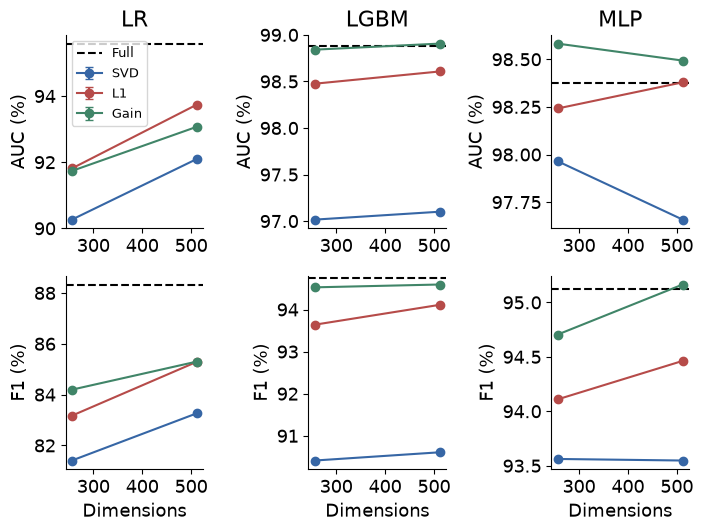

In [15]:
fig, axes = plt.subplots(2, 3, figsize=(7.2, 5.5))
for j, clf in enumerate(["LR", "LGBM", "MLP"]):
    for i, metric in enumerate(["auc", "f1"]):
        ax = axes[i, j]
        block = summary[summary.classifier == clf]
        for method in colors:
            q = block[block.method == method].sort_values("k")
            ax.errorbar(
                q.k,
                q[f"{metric}_mean"] * 100,
                yerr=q[f"{metric}_std"].fillna(0) * 100,
                marker="o",
                capsize=3,
                label=method,
                color=colors[method],
            )
        ax.axhline(
            block[block.method == "Full"][f"{metric}_mean"].iloc[0] * 100,
            color="black",
            ls="--",
            label="Full",
        )
        ax.set(
            title=clf if i == 0 else "",
            xlabel="Dimensions" if i else "",
            ylabel=metric.upper() + " (%)",
        )
axes[0, 0].legend(fontsize=9)
fig.tight_layout()
fig.savefig(FIGURES / "performance.pdf")
plt.show()


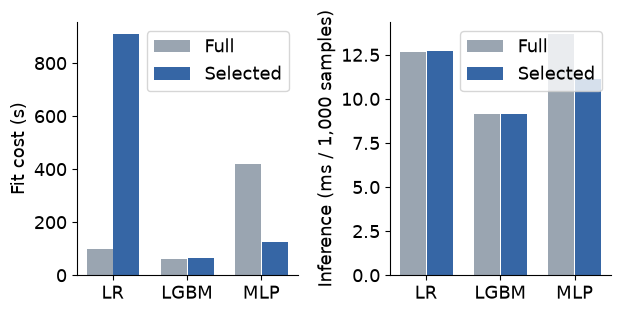

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(6.4, 3.2))
for ax, metric, title in zip(
    axes,
    ["total_fit_s", "e2e_ms_1k"],
    ["Fit cost (s)", "Inference (ms / 1,000 samples)"],
):
    for j, clf in enumerate(["LR", "LGBM", "MLP"]):
        r = selected[selected.classifier == clf].iloc[0]
        b = base[base.classifier == clf].iloc[0]
        ax.bar(
            j - 0.18,
            b[f"{metric}_mean"],
            0.35,
            color="#9aa5b1",
            label="Full" if j == 0 else None,
        )
        ax.bar(
            j + 0.18,
            r[f"{metric}_mean"],
            0.35,
            color="#3666a5",
            label="Selected" if j == 0 else None,
        )
    ax.set_xticks(range(3), ["LR", "LGBM", "MLP"])
    ax.set_ylabel(title)
    ax.legend()
fig.tight_layout()
fig.savefig(FIGURES / "efficiency.pdf")
plt.show()


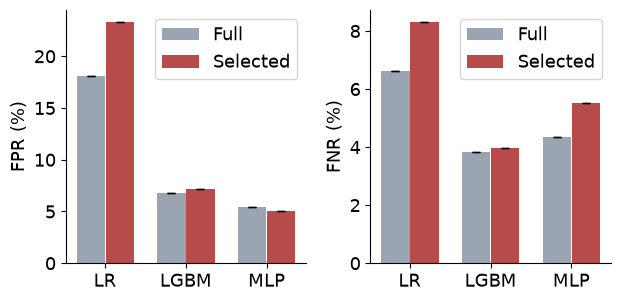

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(6.4, 3.2))
for ax, metric in zip(axes, ["fpr", "fnr"]):
    for j, clf in enumerate(["LR", "LGBM", "MLP"]):
        for offset, frame, color, label in [
            (-0.18, base, "#9aa5b1", "Full"),
            (0.18, selected, "#b64b49", "Selected"),
        ]:
            r = frame[frame.classifier == clf].iloc[0]
            sd = r[f"{metric}_std"]
            ax.bar(
                j + offset,
                100 * r[f"{metric}_mean"],
                0.35,
                yerr=0 if pd.isna(sd) else 100 * sd,
                capsize=3,
                color=color,
                label=label if j == 0 else None,
            )
    ax.set_xticks(range(3), ["LR", "LGBM", "MLP"])
    ax.set_ylabel(metric.upper() + " (%)")
    ax.legend()
fig.tight_layout()
fig.savefig(FIGURES / "errors.pdf")
plt.show()
